# NetworkX

NetworkX is a Python language software package for the creation, manipulation, and study of the structure, dynamics, and function of complex networks.

With NetworkX you can load and store networks in standard and nonstandard data formats, generate many types of random and classic networks, analyze network structure, build network models, design new network algorithms, draw networks, and much more.

Library documentation: <a>https://networkx.github.io/</a>

In [285]:
import matplotlib.pyplot as plt
import networkx as nx
G = nx.Graph()

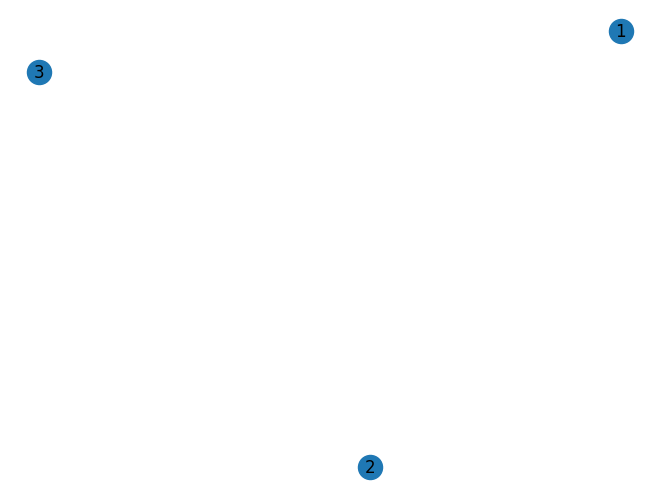

In [286]:
# basic add nodes
G.add_node(1)
G.add_nodes_from([2, 3])

nx.draw(G, with_labels=True)

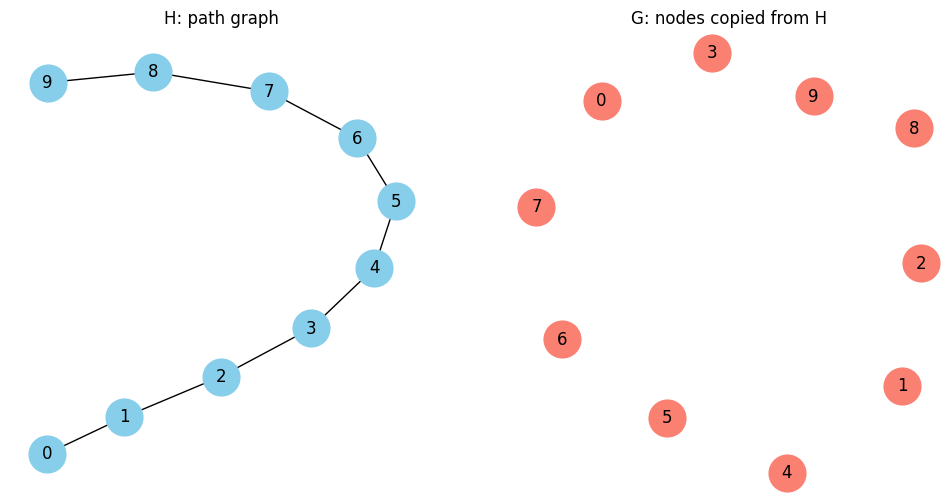

In [287]:
# add a group of nodes at once
H = nx.path_graph(10)
G.add_nodes_from(H)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

nx.draw(
    H,
    ax=axes[0],
    with_labels=True,
    node_color="skyblue",
    node_size=700
)
axes[0].set_title("H: path graph")

nx.draw(
    G,
    ax=axes[1],
    with_labels=True,
    node_color="salmon",
    node_size=700
)
axes[1].set_title("G: nodes copied from H")

plt.show()

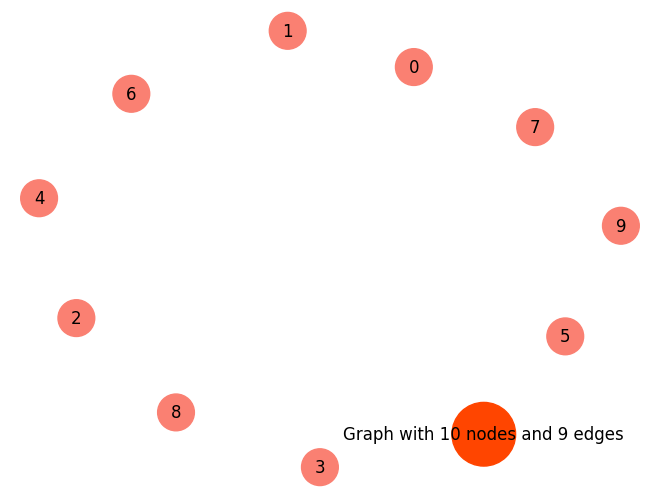

In [288]:
# add another graph itself(H: nx.path_graph(10)) as a node
G.add_node(H)

node_colors = [
    "orangered" if node is H else "salmon"
    for node in G.nodes()
]

node_sizes = [
    2100 if node is H else 700
    for node in G.nodes()
]

nx.draw(G,
        with_labels=True,
        node_size=node_sizes,
        node_color=node_colors
        )

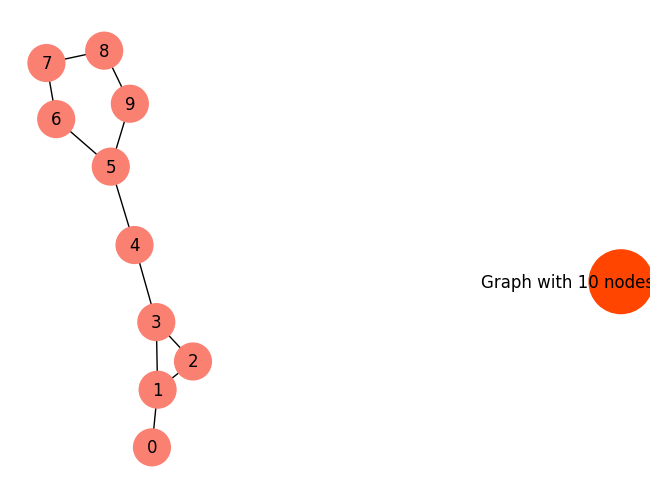

In [289]:
# add edges using similar methods
G.add_edge(1, 2)
e = (2, 3)
G.add_edge(*e)
G.add_edges_from([(5, 9), (1, 3)])
G.add_edges_from(H.edges())

node_colors = [
    "orangered" if node is H else "salmon"
    for node in G.nodes()
]

node_sizes = [
    2100 if node is H else 700
    for node in G.nodes()
]


nx.draw(
    G,
    with_labels=True,
    node_color=node_colors,
    node_size=node_sizes
)

In [290]:
# can also remove or clear
G.remove_node(H)
G.clear()

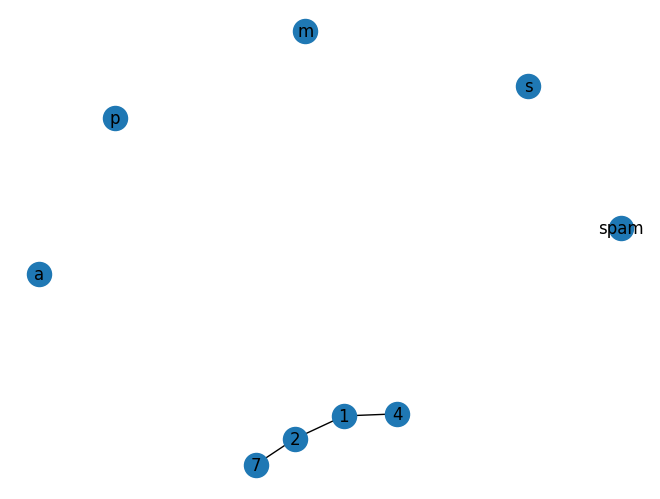

In [291]:
# repeats are ignored
G.add_edges_from([(1,2),(1,4)])
G.add_node(1)
G.add_edge(1,2)
G.add_edge(2,7)
G.add_node('spam')       # adds node "spam"
G.add_nodes_from('spam') # adds 4 nodes: 's', 'p', 'a', 'm'

nx.draw(G, with_labels=True)

In [292]:
# get the number of nodes and edges
G.number_of_nodes(), G.number_of_edges()

(9, 3)

In [293]:
# access graph edges
G[1]

AtlasView({2: {}, 4: {}})

In [294]:
G[1][2]

{}

G[1][3]:  {'color': 'orange'}


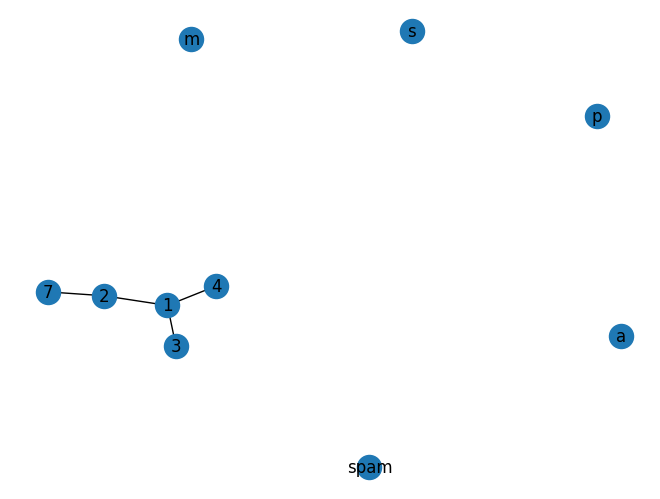

In [295]:
# set an attribute of an edge
G.add_edge(1,3)
G[1][3]['color'] = 'orange'

print("G[1][3]: ",G[1][3])

nx.draw(G, with_labels=True)

In [296]:
FG = nx.Graph()
FG.add_weighted_edges_from([(1, 2, 0.125), (1, 3, 0.75), (2, 4, 1.2), (3, 4, 0.375)])
for n, nbrs in FG.adjacency():
    for nbr, eattr in nbrs.items():
        data = eattr['weight']
        if data < 0.5: print('(%d, %d, %.3f)' % (n, nbr, data))

weights = nx.get_edge_attributes(FG, "weight")
print(weights)

(1, 2, 0.125)
(2, 1, 0.125)
(3, 4, 0.375)
(4, 3, 0.375)
{(1, 2): 0.125, (1, 3): 0.75, (2, 4): 1.2, (3, 4): 0.375}


In [297]:
# graph attribute
G = nx.Graph(day='Friday')
G.graph

{'day': 'Friday'}

In [298]:
# modifying an attribute
G.graph['day'] = 'Monday'
G.graph

{'day': 'Monday'}

In [299]:
# node attributes
G.add_node(1, time='5pm')
G.add_nodes_from([3], time='2pm')
G.nodes[1]['room'] = 714
G.nodes(data=True)

NodeDataView({1: {'time': '5pm', 'room': 714}, 3: {'time': '2pm'}})

In [300]:
# edge attributes (weight is a special numeric attribute)
G.add_edge(1, 2, weight=4.7)
G.add_edges_from([(3, 4), (4, 5)], color='red')
G.add_edges_from([(1, 2 ,{'color': 'blue'}), (2, 3, {'weight' :8})])
G[1][2]['weight'] = 4.7
G.edges[1, 2]['weight'] = 4

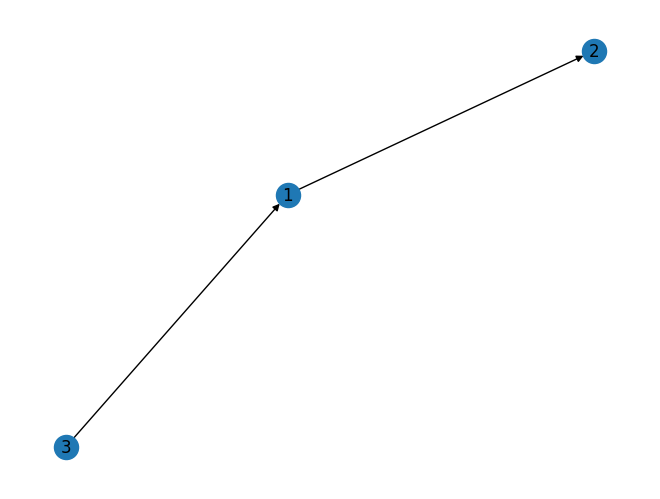

In [301]:
# directed graph
DG = nx.DiGraph()
DG.add_weighted_edges_from([(1, 2 ,0.5), (3, 1, 0.75)])

nx.draw(DG, with_labels=True) #Directed Graph라서 그래프 시각화 시, 방향이 표시 됨

In [302]:
DG.out_degree(1, weight='weight') #out degree의 간선들의 가중합

0.5

In [303]:
DG.in_degree(2) #in degree의 간선 개수만 (가중치 X)

1

In [304]:
DG.degree(1, weight='weight') #연결된 모든 간선의 가중합

1.25

In [305]:
DG.successors(1) # 후속 정점 (간선을 따라 도착하는 노드, u -> v인 경우 v)

In [306]:
DG.predecessors(1) # 선행 정점 (u -> v에서 u)

In [307]:
# convert to undirected graph
H = nx.Graph(G)

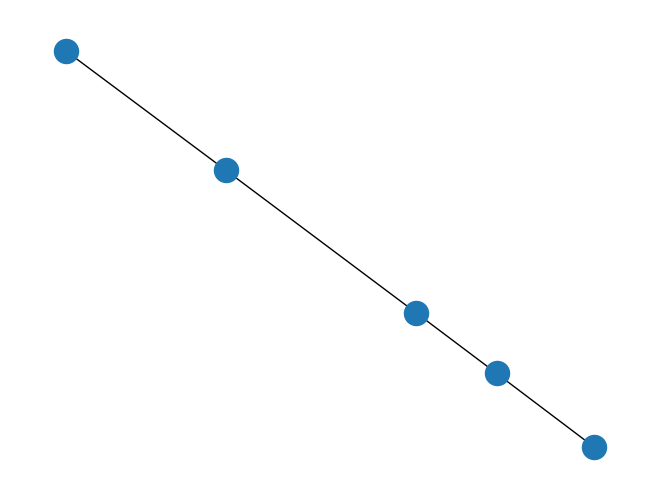

In [308]:
# basic graph drawing capability
%matplotlib inline
import matplotlib.pyplot as plt
nx.draw(G)